# SemEval 2026 Task 11 — Subtask 3: Multilingual 4-Label Syllogism Classifier
## Valid/Invalid × Plausible/Implausible | Qwen3-1.7B + **Unsloth** + LoRA + Cross-CoT | T4 Optimized


In [ ]:
# ============================================================
# CELL 1: Install Dependencies (Unsloth + supporting libs)
# ============================================================
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# Unsloth must be installed before transformers imports
!pip install -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install -q --no-deps "trl<0.9.0" peft accelerate bitsandbytes
!pip install -q datasets scikit-learn matplotlib seaborn sentencepiece protobuf
print("All dependencies installed ✅")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 128.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 842.7/842.7 kB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 116.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.2/185.2 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 114.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.0/225.0 kB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.2/245.2 kB 9.2 MB/

In [ ]:
# ============================================================
# CELL 2: Imports & Configuration
# ============================================================
import os, gc, random, warnings
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from unsloth import FastModel           # Unsloth fast loader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    EarlyStoppingCallback,
    TrainingArguments,
    Trainer,
)
from peft import LoraConfig, get_peft_model, TaskType
from datasets import Dataset
from sklearn.metrics import (
    f1_score, accuracy_score, precision_score,
    recall_score, confusion_matrix, classification_report,
)
from sklearn.model_selection import train_test_split

# ─── Reproducibility ──────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# ─── Model ────────────────────────────────────────────────────
MODEL_NAME = "unsloth/Qwen3-1.7B-unsloth-bnb-4bit"   # pre-quantised for Unsloth
NUM_LABELS = 4

# ─── Label Map ────────────────────────────────────────────────
LABEL2ID = {
    "valid and plausible":     0,
    "valid and implausible":   1,
    "invalid and plausible":   2,
    "invalid and implausible": 3,
}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# ─── Hyperparameters  ← tune these between runs ───────────────
LEARNING_RATE   = 2e-4     # try 1e-4 / 3e-4
MAX_EPOCHS      = 11       # 15-20 epochs recommended
PATIENCE        = 8        # early-stopping patience
BATCH_SIZE      = 2        # per-device (T4 safe)
GRAD_ACCUM      = 4        # effective batch = 2 × 4 = 8
MAX_SEQ_LEN     = 612     # token budget per sample
TEMPERATURE     = 0.9      # inference softmax temperature
WRITE_WEIGHTS   = True

# ─── LoRA ─────────────────────────────────────────────────────
LORA_R          = 16        # rank  — try 16 / 32
LORA_ALPHA      = 32     # scaling — usually 2 × LORA_R
LORA_DROPOUT    = 0.2

# ─── Paths ────────────────────────────────────────────────────
TRAIN_CSV_PATH       = "/content/train_data_49_51_ratio.csv"
TEST_CSV_PATH        = "/content/test_data_multilang_CSV.csv"
TEST_LABELS_CSV_PATH = "/content/test_data_subtask_3_with_labels.csv"
OUTPUT_DIR           = "/content/semeval_multilang"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device         : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU            : {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory     : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

print(f"\n{'='*60}")
print("CONFIGURATION")
print(f"{'='*60}")
print(f"  MODEL         : {MODEL_NAME}")
print(f"  NUM_LABELS    : {NUM_LABELS}  (4-class)")
print(f"  LEARNING_RATE : {LEARNING_RATE}")
print(f"  MAX_EPOCHS    : {MAX_EPOCHS}  (patience={PATIENCE})")
print(f"  BATCH_SIZE    : {BATCH_SIZE}  (effective={BATCH_SIZE*GRAD_ACCUM})")
print(f"  MAX_SEQ_LEN   : {MAX_SEQ_LEN}")
print(f"  LORA_R/ALPHA  : {LORA_R} / {LORA_ALPHA}")
print(f"  LABEL MAP     : {LABEL2ID}")
print("Configuration ready ✅")


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
Device         : cuda
GPU            : Tesla T4
GPU Memory     : 15.6 GB

CONFIGURATION
  MODEL         : unsloth/Qwen3-1.7B-unsloth-bnb-4bit
  NUM_LABELS    : 4  (4-class)
  LEARNING_RATE : 0.0002
  MAX_EPOCHS    : 11  (patience=8)
  BATCH_SIZE    : 2  (effective=8)
  MAX_SEQ_LEN   : 612
  LORA_R/ALPHA  : 16 / 32
  LABEL MAP     : {'valid and plausible': 0, 'valid and implausible': 1, 'invalid and plausible': 2, 'invalid and implausible': 3}
Configuration ready ✅


In [ ]:
# ============================================================
# CELL 3: Cross-CoT Prompt  (< 500 tokens)
# Structure: Definitions → 3-Step Method → 3 Labelled Examples
# ============================================================

COT_SYSTEM_PROMPT =  """Classify syllogism. Labels: valid and plausible | valid and implausible | invalid and plausible | invalid and implausible
VALIDITY: conclusion follows logically from premises. PLAUSIBILITY: content matches real-world facts.
Steps: (1) validity: counterexample possible?→invalid else valid (2) plausibility: believable?→plausible else implausible

[EN/DE] All chairs are birds. All birds are furniture. → all chairs are furniture.
V:valid | P:implausible → valid and implausible

[EN/ZH] All dogs are animals. All animals breathe. → all dogs breathe.
V:valid | P:plausible → valid and plausible

[EN/BN] Some fish are shirts. All shirts are cats. → no fish are cats.
V:invalid | P:implausible → invalid and implausible

[EN/FR] Some trees are vehicles. All vehicles are clothes. → no trees are clothes.
V:invalid | P:plausible → invalid and plausible

[EN/IT] Some doctors are shirts. All shirts are fruit. → no doctors are fruit.
V:invalid | P:plausible → invalid and plausible

[EN/ES] All birds are chairs. All chairs are plants. → all birds are plants.
V:valid | P:implausible → valid and implausible

[EN/RU] Some plants are cars. All cars are hammers. → no plants are hammers.
V:invalid | P:plausible → invalid and plausible

[EN/SW] All mammals are doctors. All doctors are furniture. → all mammals are furniture.
V:valid | P:implausible → valid and implausible

[EN/PT] Some dogs are shirts. All shirts are doctors. → no dogs are doctors.
V:invalid | P:implausible → invalid and implausible

[EN/NL] Every human is a robot. Any child is a human. → every child is a robot.
V:valid | P:implausible → valid and implausible

[EN/TE] All apples are vehicles. All vehicles are professions. → all apples are professions.
V:valid | P:implausible → valid and implausible

[EN/ZH-CN] Some shirts are cars. All cars are hammers. → no shirts are hammers.
V:invalid | P:plausible → invalid and plausible"""

def build_cot_input(syllogism: str) -> str:
    """Wrap syllogism with Cross-CoT prompt for SEQ_CLS input."""
    return f"{COT_SYSTEM_PROMPT}\n\nSyllogism: {syllogism}\n\nAnalyze and classify:"


# ── Token budget check ────────────────────────────────────────
sample_text    = build_cot_input("All cats are animals. No animals are plants. So no cats are plants.")
approx_tokens  = len(sample_text.split()) * 1.3
print(f"Prompt chars   : {len(sample_text)}")
print(f"Approx tokens  : {approx_tokens:.0f}  (prompt only, target <500)")
print("CoT Prompt ready ✅")


Prompt chars   : 2000
Approx tokens  : 404  (prompt only, target <500)
CoT Prompt ready ✅


In [ ]:
# ============================================================
# CELL 4: Load & Inspect Data
# ============================================================

train_df = pd.read_csv(TRAIN_CSV_PATH)
test_df  = pd.read_csv(TEST_CSV_PATH)

# Normalise & validate labels
train_df["label"] = train_df["label"].str.strip()
unknown = set(train_df["label"].unique()) - set(LABEL2ID.keys())
assert not unknown, f"Unknown labels in train: {unknown}"

train_df["label_id"] = train_df["label"].map(LABEL2ID)

print(f"Train shape   : {train_df.shape}")
print(f"Test  shape   : {test_df.shape}")
print(f"\nLabel distribution (train):")
print(train_df["label"].value_counts())
print(f"\nLanguages (train):")
print(train_df["lang"].value_counts())
print(f"\nLanguages (test):")
print(test_df["lang"].value_counts())
print("\nData loaded ✅")


Train shape   : (1000, 6)
Test  shape   : (192, 4)

Label distribution (train):
label
invalid and implausible    255
invalid and plausible      255
valid and implausible      245
valid and plausible        245
Name: count, dtype: int64

Languages (train):
lang
it       98
es       94
de       93
te       93
bn       92
fr       90
sw       88
ru       88
pt       86
nl       85
zh       75
zh-CN    18
Name: count, dtype: int64

Languages (test):
lang
it       18
es       18
fr       18
zh-CN    18
de       18
te       17
sw       17
pt       17
nl       17
bn       17
ru       17
Name: count, dtype: int64

Data loaded ✅


In [ ]:
# ============================================================
# CELL 5: Stratified Train / Validation Split
# ============================================================

train_split, val_split = train_test_split(
    train_df,
    test_size=0.15,
    random_state=SEED,
    stratify=train_df["label_id"],
)
train_split = train_split.reset_index(drop=True)
val_split   = val_split.reset_index(drop=True)

overlap = set(train_split["syllogism"]) & set(val_split["syllogism"])
assert len(overlap) == 0, f"Data leakage! {len(overlap)} overlapping syllogisms"

print(f"Train samples : {len(train_split)}")
print(f"Val   samples : {len(val_split)}")
print(f"Overlap       : {len(overlap)} ✅ clean split")
print(f"Train label dist : {train_split['label_id'].value_counts().sort_index().to_dict()}")
print(f"Val   label dist : {val_split['label_id'].value_counts().sort_index().to_dict()}")
print("Split ready ✅")


Train samples : 850
Val   samples : 150
Overlap       : 0 ✅ clean split
Train label dist : {0: 208, 1: 208, 2: 217, 3: 217}
Val   label dist : {0: 37, 1: 37, 2: 38, 3: 38}
Split ready ✅


In [ ]:
# ============================================================
# CELL 6: Load Model via Unsloth + SEQ_CLS Head
# ============================================================
import gc, os, torch
import torch.nn as nn
from unsloth import FastModel
from peft import LoraConfig, get_peft_model, TaskType
from transformers import PreTrainedModel, PretrainedConfig
from transformers.modeling_outputs import SequenceClassifierOutput

gc.collect()
torch.cuda.empty_cache()

# ── Step 1: Load 4-bit backbone ──────────────────
print(f"Loading backbone via Unsloth: {MODEL_NAME}")
backbone, tokenizer = FastModel.from_pretrained(
    model_name     = MODEL_NAME,
    max_seq_length = MAX_SEQ_LEN,
    load_in_4bit   = True,
    dtype          = None,
)
if tokenizer.pad_token is None:
    tokenizer.pad_token    = tokenizer.eos_token
    tokenizer.pad_token_id = tokenizer.eos_token_id
tokenizer.padding_side = "right"
backbone.config.pad_token_id = tokenizer.pad_token_id

# ── Step 2: Apply LoRA ───────────
lora_config = LoraConfig(
    r              = LORA_R,
    lora_alpha     = LORA_ALPHA,
    target_modules = "all-linear",
    lora_dropout   = LORA_DROPOUT,
    bias           = "none",
    task_type      = TaskType.FEATURE_EXTRACTION,
)
backbone = get_peft_model(backbone, lora_config)

# ── Step 3: Wrap for SeqCLS ─────
class SeqCLSConfig(PretrainedConfig):
    model_type = "unsloth_seqcls"
    def __init__(self, backbone_config=None, num_labels=4, **kwargs):
        super().__init__(**kwargs)
        self.hidden_size = backbone_config.hidden_size if backbone_config else 2048
        self.num_labels  = num_labels
        self.id2label    = ID2LABEL
        self.label2id    = LABEL2ID

class UnslothForSeqCLS(PreTrainedModel):
    config_class = SeqCLSConfig
    supports_gradient_checkpointing = True

    def __init__(self, config, backbone):
        super().__init__(config)
        self.backbone   = backbone
        self.classifier = nn.Linear(config.hidden_size, config.num_labels)
        self.loss_fn    = nn.CrossEntropyLoss()

    def forward(self, input_ids=None, attention_mask=None, labels=None, **kwargs):
        # Fix: Accept **kwargs to prevent 'num_items_in_batch' warnings
        out = self.backbone(
            input_ids        = input_ids,
            attention_mask   = attention_mask,
            output_hidden_states = True,
            **kwargs # Pass kwargs like num_items_in_batch to backbone if supported
        )
        hidden    = out.hidden_states[-1]
        seq_lens  = attention_mask.sum(dim=1) - 1
        pooled    = hidden[torch.arange(hidden.size(0), device=hidden.device), seq_lens]
        logits    = self.classifier(pooled.float())

        loss = None
        if labels is not None:
            loss = self.loss_fn(logits, labels)
        return SequenceClassifierOutput(loss=loss, logits=logits)

cls_config = SeqCLSConfig(backbone_config=backbone.config, num_labels=NUM_LABELS)
model = UnslothForSeqCLS(cls_config, backbone)

for p in model.classifier.parameters(): p.requires_grad = True
model.classifier = model.classifier.to(next(backbone.parameters()).device)

print("Unsloth backbone + SEQ_CLS head updated to handle kwargs ✅")

Loading backbone via Unsloth: unsloth/Qwen3-1.7B-unsloth-bnb-4bit
==((====))==  Unsloth 2026.5.4: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/1.41G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/237 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

added_tokens.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

unsloth/Qwen3-1.7B-unsloth-bnb-4bit does not have a padding token! Will use pad_token = <|PAD_TOKEN|>.
Unsloth backbone + SEQ_CLS head updated to handle kwargs ✅


In [ ]:
# ============================================================
# CELL 7: Tokenize & Build HuggingFace Datasets
# ============================================================

def build_cls_dataset(df, tokenizer, has_labels=True):
    """Tokenize Cross-CoT inputs. Logs any row-level errors (no silent data loss)."""
    input_ids_list      = []
    attention_mask_list = []
    labels_list         = []
    skipped             = 0

    for _, row in df.iterrows():
        try:
            text    = build_cot_input(str(row["syllogism"]))
            encoded = tokenizer(
                text,
                max_length  = MAX_SEQ_LEN,
                padding     = "max_length",
                truncation  = True,
                return_tensors = "pt",
            )
            input_ids_list.append(encoded["input_ids"].squeeze().tolist())
            attention_mask_list.append(encoded["attention_mask"].squeeze().tolist())
            if has_labels:
                labels_list.append(int(row["label_id"]))
        except Exception as e:
            skipped += 1
            print(f"  [WARN] Skipped row {_}: {e}")

    if skipped:
        print(f"  ⚠️  Skipped {skipped} rows. Check data above.")

    result = {"input_ids": input_ids_list, "attention_mask": attention_mask_list}
    if has_labels:
        result["labels"] = labels_list
    return Dataset.from_dict(result)


print("Building tokenized datasets...")
train_dataset = build_cls_dataset(train_split, tokenizer, has_labels=True)
val_dataset   = build_cls_dataset(val_split,   tokenizer, has_labels=True)
print(f"  train_dataset : {len(train_dataset)} samples")
print(f"  val_dataset   : {len(val_dataset)} samples")
assert len(train_dataset) == len(train_split), "Train data loss detected!"
assert len(val_dataset)   == len(val_split),   "Val data loss detected!"
print("Datasets ready — no data loss ✅")


Building tokenized datasets...
  train_dataset : 850 samples
  val_dataset   : 150 samples
Datasets ready — no data loss ✅


In [ ]:
# ============================================================
# CELL 8: Training (Unsloth-accelerated)
# gradient_checkpointing disabled — avoids hook conflicts with
# 4-bit quantised layers inside custom wrapper.
# Memory is managed via small batch + grad accumulation instead.
# ============================================================
import numpy as np
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback
from sklearn.metrics import f1_score, accuracy_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "f1":       f1_score(labels, preds, average="macro", zero_division=0),
        "accuracy": accuracy_score(labels, preds),
    }

warmup_steps = max(1, int(0.1 * len(train_dataset) / (BATCH_SIZE * GRAD_ACCUM)))

training_args = TrainingArguments(
    output_dir                  = OUTPUT_DIR,
    num_train_epochs            = MAX_EPOCHS,        # set to 15-20 in config
    per_device_train_batch_size = BATCH_SIZE,
    per_device_eval_batch_size  = BATCH_SIZE,
    gradient_accumulation_steps = GRAD_ACCUM,
    learning_rate               = LEARNING_RATE,
    lr_scheduler_type           = "cosine",
    warmup_steps                = warmup_steps,
    optim                       = "adamw_8bit",
    weight_decay                = 0.01,
    max_grad_norm               = 1.0,
    eval_strategy               = "epoch",
    save_strategy               = "epoch",
    metric_for_best_model       = "f1",
    greater_is_better           = True,
    load_best_model_at_end      = True,
    save_total_limit            = 2,
    bf16                        = False,
    fp16                        = False,
    logging_steps               = 5,
    report_to                   = "none",
    seed                        = SEED,
    dataloader_num_workers      = 0,
    gradient_checkpointing      = False,   # off — avoids hook conflict with 4-bit wrapper
    remove_unused_columns       = False,   # keep all columns; custom model needs them
)

early_stopping = EarlyStoppingCallback(
    early_stopping_patience  = PATIENCE,
    early_stopping_threshold = 0.001,
)

trainer = Trainer(
    model           = model,
    args            = training_args,
    train_dataset   = train_dataset,
    eval_dataset    = val_dataset,
    compute_metrics = compute_metrics,
    callbacks       = [early_stopping],
)

print("=" * 65)
print("STARTING TRAINING — Unsloth + 4-Class Multilingual SEQ_CLS")
print(f"  model           : {MODEL_NAME}")
print(f"  epochs          : {MAX_EPOCHS}  (patience={PATIENCE})")
print(f"  learning_rate   : {LEARNING_RATE}")
print(f"  effective batch : {BATCH_SIZE} × {GRAD_ACCUM} = {BATCH_SIZE*GRAD_ACCUM}")
print(f"  train samples   : {len(train_dataset)}")
print(f"  val samples     : {len(val_dataset)}")
print(f"  warmup steps    : {warmup_steps}")
print("=" * 65)

train_result = trainer.train()

print("\n" + "=" * 65)
print("TRAINING COMPLETE")
print("=" * 65)
print(f"Training loss   : {train_result.training_loss:.4f}")
print(f"Runtime         : {train_result.metrics.get('train_runtime', 0):.0f}s")
if torch.cuda.is_available():
    print(f"Peak GPU memory : {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

loss = train_result.training_loss
if loss < 0.5:
    print(f"\n✅ Loss {loss:.4f} — good! Target 85%+ F1 achievable")
elif loss < 0.8:
    print(f"\n⚠️  Loss {loss:.4f} — consider more epochs or lower LR")
else:
    print(f"\n❌ Loss {loss:.4f} — increase epochs, check prompt/data")


STARTING TRAINING — Unsloth + 4-Class Multilingual SEQ_CLS
  model           : unsloth/Qwen3-1.7B-unsloth-bnb-4bit
  epochs          : 11  (patience=8)
  learning_rate   : 0.0002
  effective batch : 2 × 4 = 8
  train samples   : 850
  val samples     : 150
  warmup steps    : 10


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 850 | Num Epochs = 11 | Total steps = 1,177
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 17,440,772 of 1,052,247,044 (1.66% trained)
Unsloth: Not an error, but UnslothForSeqCLS does not accept `num_items_in_batch`.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss,F1,Accuracy
1,0.818648,1.000005,0.340885,0.480000
2,0.922157,0.854768,0.320996,0.460000
3,0.802884,0.841554,0.316094,0.473333
4,0.887397,0.906638,0.307991,0.446667
5,0.744764,0.762869,0.469917,0.526667
6,0.866487,0.848747,0.419551,0.506667
7,0.722784,0.842740,0.459059,0.460000
8,0.336675,0.977143,0.489916,0.506667
9,0.503203,1.119896,0.510886,0.513333
10,0.201217,1.628034,0.479574,0.480000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['backbone.base_model.model.lm_head.weight'].
There were unexpected keys in the checkpoint model loaded: ['backbone.base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.nested_absmax', 'backbone.base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.nested_quant_map', 'backbone.base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.quant_map', 'backbone.base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.absmax', 'backbone.base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.quant_state.bitsandbytes__nf4', 'backbone.base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight.nested_absmax', 'backbone.base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight.nested_quant_map', 'backbone.base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight.quant_map', 'backbone.base_model.model.model.layers.0.self_attn.k_proj.base_layer.weight.absmax', '


TRAINING COMPLETE
Training loss   : 0.6396
Runtime         : 5302s
Peak GPU memory : 2.20 GB

⚠️  Loss 0.6396 — consider more epochs or lower LR


In [ ]:
# ============================================================
# CELL 9: Predict on Test Data + Save Predictions
# ============================================================

def predict_labels(model, tokenizer, syllogisms, temperature=1.0, batch_size=8):
    """Batched inference with optional temperature scaling."""
    model.eval()
    predictions = []
    n = len(syllogisms)

    for i in range(0, n, batch_size):
        batch  = syllogisms[i : i + batch_size]
        texts  = [build_cot_input(str(s)) for s in batch]
        inputs = tokenizer(
            texts,
            max_length     = MAX_SEQ_LEN,
            padding        = "max_length",
            truncation     = True,
            return_tensors = "pt",
        ).to(model.device)

        with torch.no_grad():
            logits = model(**inputs).logits
            if temperature != 1.0:
                logits = logits / temperature
            preds  = torch.argmax(logits, dim=-1).cpu().tolist()
        predictions.extend(preds)

        done = min(i + batch_size, n)
        if done % 40 == 0 or done == n:
            print(f"  [{done:>3}/{n}] predicted...")

    return [ID2LABEL[p] for p in predictions]


print(f"Running inference on {len(test_df)} test samples...")
test_predictions = predict_labels(
    model, tokenizer,
    test_df["syllogism"].tolist(),
    temperature = TEMPERATURE,
)

# ── Verify no data loss in predictions ────────────────────────
assert len(test_predictions) == len(test_df), "Prediction count mismatch!"

# ── Save to CSV ───────────────────────────────────────────────
pred_df   = test_df.copy()
pred_df["predicted_label"] = test_predictions
pred_path = os.path.join(OUTPUT_DIR, "test_predictions.csv")
pred_df.to_csv(pred_path, index=False)

print(f"\nPredicted label distribution:")
print(pd.Series(test_predictions).value_counts())
print(f"\nPredictions saved → {pred_path} ✅")


Running inference on 192 test samples...
  [ 40/192] predicted...
  [ 80/192] predicted...
  [120/192] predicted...
  [160/192] predicted...
  [192/192] predicted...

Predicted label distribution:
valid and plausible        48
invalid and plausible      48
invalid and implausible    48
valid and implausible      48
Name: count, dtype: int64

Predictions saved → /content/semeval_multilang/test_predictions.csv ✅


EVALUATION RESULTS
Metric                         Value
----------------------------------------
Macro F1                      0.9426  ← SemEval primary metric
Micro F1                      0.9427
Weighted F1                   0.9428
Macro Precision               0.9427
Macro Recall                  0.9429
Accuracy                      0.9427

🎯 SemEval MACRO F1: 94.26%  ✅ TARGET MET (>85%)

PER-CLASS CLASSIFICATION REPORT
                         precision    recall  f1-score   support

    valid and plausible       0.94      0.94      0.94        48
  valid and implausible       0.94      0.94      0.94        48
  invalid and plausible       0.92      0.96      0.94        46
invalid and implausible       0.98      0.94      0.96        50

               accuracy                           0.94       192
              macro avg       0.94      0.94      0.94       192
           weighted avg       0.94      0.94      0.94       192



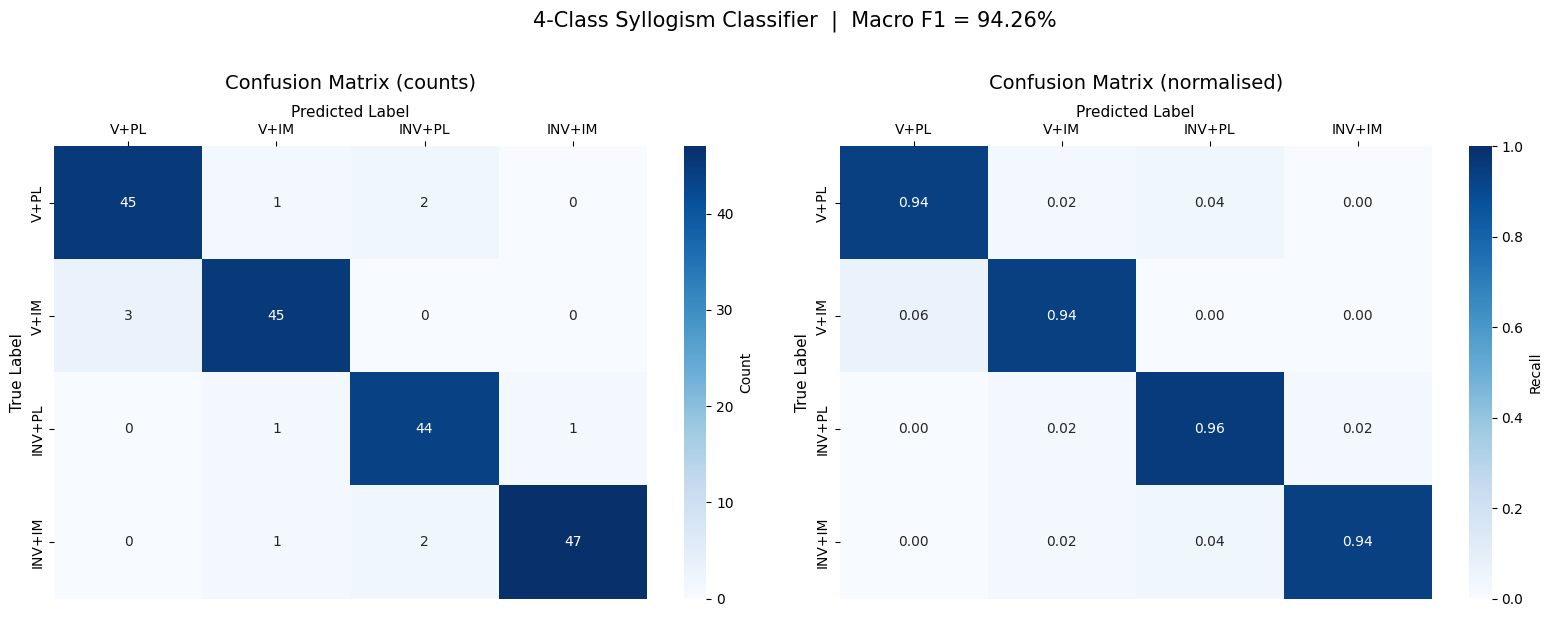

Confusion matrix saved → /content/semeval_multilang/confusion_matrix.png ✅

PER-LANGUAGE MACRO F1 BREAKDOWN
  bn        n= 17  macro_f1=0.8673
  de        n= 18  macro_f1=1.0000
  es        n= 18  macro_f1=0.9451
  fr        n= 18  macro_f1=1.0000
  it        n= 18  macro_f1=0.8816
  nl        n= 17  macro_f1=0.9365
  pt        n= 17  macro_f1=0.9495
  ru        n= 17  macro_f1=1.0000
  sw        n= 17  macro_f1=0.8365
  te        n= 17  macro_f1=1.0000
  zh-CN     n= 18  macro_f1=0.8395


In [ ]:
# ============================================================
# CELL 10: Evaluate Against Gold Labels + Full Metrics + Confusion Matrix
# ============================================================

gold_df  = pd.read_csv(TEST_LABELS_CSV_PATH)
gold_df["label"] = gold_df["label"].str.strip()

eval_df  = pred_df.merge(gold_df[["id", "label"]], on="id", how="inner")
eval_df  = eval_df.rename(columns={"label": "true_label"})
assert len(eval_df) == len(pred_df), f"Merge mismatch: {len(pred_df)} preds vs {len(eval_df)} matched"

y_true   = eval_df["true_label"].tolist()
y_pred   = eval_df["predicted_label"].tolist()
classes  = list(LABEL2ID.keys())

# ── Compute all 4 metrics ─────────────────────────────────────
f1_macro  = f1_score(y_true, y_pred, average="macro",    labels=classes, zero_division=0)
f1_micro  = f1_score(y_true, y_pred, average="micro",    labels=classes, zero_division=0)
f1_weight = f1_score(y_true, y_pred, average="weighted", labels=classes, zero_division=0)
prec      = precision_score(y_true, y_pred, average="macro",    labels=classes, zero_division=0)
rec       = recall_score(y_true, y_pred,    average="macro",    labels=classes, zero_division=0)
acc       = accuracy_score(y_true, y_pred)

print("=" * 70)
print("EVALUATION RESULTS")
print("=" * 70)
print(f"{'Metric':<25} {'Value':>10}")
print("-" * 40)
print(f"{'Macro F1':<25} {f1_macro:>10.4f}  ← SemEval primary metric")
print(f"{'Micro F1':<25} {f1_micro:>10.4f}")
print(f"{'Weighted F1':<25} {f1_weight:>10.4f}")
print(f"{'Macro Precision':<25} {prec:>10.4f}")
print(f"{'Macro Recall':<25} {rec:>10.4f}")
print(f"{'Accuracy':<25} {acc:>10.4f}")
print("=" * 70)
print(f"\n🎯 SemEval MACRO F1: {f1_macro*100:.2f}%  {'✅ TARGET MET (>85%)' if f1_macro >= 0.85 else '❌ Below 85% — tune hyperparams'}")

# ── Per-class report ──────────────────────────────────────────
print("\n" + "=" * 70)
print("PER-CLASS CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report(y_true, y_pred, labels=classes, zero_division=0))

# ── Confusion Matrix (counts + normalised) ────────────────────
cm          = confusion_matrix(y_true, y_pred, labels=classes)
short_labels = ["V+PL", "V+IM", "INV+PL", "INV+IM"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm, annot=True, fmt="d", ax=axes[0],
            xticklabels=short_labels, yticklabels=short_labels,
            cmap="Blues", cbar_kws={"label": "Count"})
axes[0].set_title("Confusion Matrix (counts)", fontsize=14, pad=12)
axes[0].set_ylabel("True Label", fontsize=11)
axes[0].set_xlabel("Predicted Label", fontsize=11)
axes[0].xaxis.set_label_position("top"); axes[0].xaxis.tick_top()

cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", ax=axes[1],
            xticklabels=short_labels, yticklabels=short_labels,
            cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "Recall"})
axes[1].set_title("Confusion Matrix (normalised)", fontsize=14, pad=12)
axes[1].set_ylabel("True Label", fontsize=11)
axes[1].set_xlabel("Predicted Label", fontsize=11)
axes[1].xaxis.set_label_position("top"); axes[1].xaxis.tick_top()

plt.suptitle(f"4-Class Syllogism Classifier  |  Macro F1 = {f1_macro*100:.2f}%",
             fontsize=15, y=1.02)
plt.tight_layout()
cm_path = os.path.join(OUTPUT_DIR, "confusion_matrix.png")
plt.savefig(cm_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Confusion matrix saved → {cm_path} ✅")

# ── Per-language F1 ───────────────────────────────────────────
print("\n" + "=" * 70)
print("PER-LANGUAGE MACRO F1 BREAKDOWN")
print("=" * 70)
eval_df["correct"] = (eval_df["true_label"] == eval_df["predicted_label"])
for lang, grp in eval_df.groupby("lang"):
    lang_f1 = f1_score(grp["true_label"], grp["predicted_label"],
                       average="macro", labels=classes, zero_division=0)
    print(f"  {lang:<8}  n={len(grp):>3}  macro_f1={lang_f1:.4f}")


In [ ]:
import pandas as pd
from google.colab import files

# Prepare the data for the Excel report
report_data = {
    "Hyperparameter/Metric": [
        "Epochs", "Patience", "LoRA R", "LoRA Alpha", "LoRA Dropout", "Temperature",
        "Macro F1", "Micro F1", "Macro Precision", "Macro Recall", "Accuracy"
    ],
    "Value": [
        MAX_EPOCHS, PATIENCE, LORA_R, LORA_ALPHA, LORA_DROPOUT, TEMPERATURE,
        f1_macro, f1_micro, prec, rec, acc
    ]
}

# Create DataFrame
report_df = pd.DataFrame(report_data)

# Define filename
report_filename = "model_performance_report.xlsx"

# Save to Excel
report_df.to_excel(report_filename, index=False)

# Trigger direct download
print(f"Downloading {report_filename}...")
files.download(report_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CELL 11: Save Model (Both formats) + All Outputs to Google Drive
# ============================================================
from google.colab import drive
import torch
import os
import shutil
import time

drive.mount("/content/drive")
print("Google Drive mounted ✅")

TASK      = "multilang_4class_unsloth"
DRIVE_DIR = f"/content/drive/MyDrive/SemEval2026/92model/{TASK}"

# ── Ensure directories exist ──────────────────────────────────
adapter_path = f"{DRIVE_DIR}/lora_adapter"
tok_path     = f"{DRIVE_DIR}/tokenizer"
os.makedirs(adapter_path, exist_ok=True)
os.makedirs(tok_path, exist_ok=True)

# Small pause to allow Drive fuse layer to sync
time.sleep(2)

# 1. Save via HuggingFace (Safetensors + bin)
# This helps create the directory structure if it's missing
print("Saving HuggingFace formats...")
model.save_pretrained(adapter_path, safe_serialization=True)
model.save_pretrained(adapter_path, safe_serialization=False)

# 2. Explicitly save the PyTorch .pt state dict
print("Saving explicit .pt state dict...")
pt_model_path = os.path.join(adapter_path, "pytorch_model.pt")

# Double check existence before torch.save to prevent RuntimeError
if not os.path.exists(adapter_path):
    os.makedirs(adapter_path, exist_ok=True)

torch.save(model.state_dict(), pt_model_path)

print(f"  ✅ Model saved in .safetensors, .bin, and .pt formats → {adapter_path}")

# ── Save tokenizer ────────────────────────────────────────────
tokenizer.save_pretrained(tok_path)
print(f"  ✅ Tokenizer    → {tok_path}")

# ── Copy predictions + confusion matrix ───────────────────────
shutil.copy(pred_path, f"{DRIVE_DIR}/test_predictions.csv")
shutil.copy(cm_path, f"{DRIVE_DIR}/confusion_matrix.png")

print("\n" + "=" * 60)
print("ALL FILES SAVED TO GOOGLE DRIVE ✅")
print("=" * 60)
for root, _, files in os.walk(DRIVE_DIR):
    for fname in sorted(files):
        fpath = os.path.join(root, fname)
        fsize = os.path.getsize(fpath) / (1024**2)
        print(f"  {fpath.replace(DRIVE_DIR,'')}  →  {fsize:.1f} MB")

Mounted at /content/drive
Google Drive mounted ✅
Saving HuggingFace formats...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saving explicit .pt state dict...
  ✅ Model saved in .safetensors, .bin, and .pt formats → /content/drive/MyDrive/SemEval2026/92model/multilang_4class_unsloth/lora_adapter


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/SemEval2026/92model/multilang_4class_unsloth/tokenizer/tokenizer_config.json.


  ✅ Tokenizer    → /content/drive/MyDrive/SemEval2026/92model/multilang_4class_unsloth/tokenizer

ALL FILES SAVED TO GOOGLE DRIVE ✅
  /confusion_matrix.png  →  0.1 MB
  /test_predictions.csv  →  0.1 MB
  /lora_adapter/config.json  →  0.0 MB
  /lora_adapter/model.safetensors  →  1407.5 MB
  /lora_adapter/pytorch_model.pt  →  1408.1 MB
  /tokenizer/chat_template.jinja  →  0.0 MB
  /tokenizer/tokenizer.json  →  10.9 MB
  /tokenizer/tokenizer_config.json  →  0.0 MB
